# Drift Atlas data validation

## tl;dr

The downloaded 2024 western North Atlantic extract contains **65,625 six-hour position records from 150 drifters**. IDs, timestamps and coordinates are complete, and no duplicate `ID + time` keys were found. NOAA uses `-999999` as a velocity fill value in 83 rows, so the analysis converts those values to missing before calculating speed. Sea-surface temperature is missing in 6,690 rows. Coverage varies considerably by month and place, which means the final interface must show the track count and search window with every result.


## Context and methods

This notebook checks the working extract planned for the first Drift Atlas prototype.

- Source: NOAA Global Drifter Program, 6-hour interpolated quality-controlled data
- Source page: https://erddap.aoml.noaa.gov/gdp/erddap/info/drifter_6hour_qc/index.html
- DOI: https://doi.org/10.25921/7ntx-z961
- Accessed: October 22, 2026
- Time filter: January 1 through December 31, 2024 UTC
- Geographic filter: 30°N to 50°N and 75°W to 40°W
- Grain: one quality-controlled, interpolated position estimate for one drifter at one six-hour timestamp

### Key assumptions

The regional query only returns positions inside the selected bounding box. A gap in one drifter's local record may therefore mean that the instrument left the box and later returned. It does not automatically mean NOAA failed to collect data.


## Data

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_dir = Path.cwd()
if not (project_dir / "scripts").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from scripts.analyze_data import load_data, numeric_summary

data = load_data()
results = json.loads((project_dir / "analysis/validation_results.json").read_text())

print(f"Rows: {len(data):,}")
print(f"Downloaded columns: {results['columns_in_download']}")
print(f"Unique drifters: {data['ID'].nunique():,}")
print(f"Time range: {data['time'].min()} to {data['time'].max()}")
data.head()

Rows: 65,625
Downloaded columns: 8
Unique drifters: 150
Time range: 2024-01-01 00:00:00+00:00 to 2024-12-31 18:00:00+00:00


,ID,time,latitude,longitude,ve,vn,sst,drogue_lost_date,speed_m_s,month,drogue_status,lat_bin_start,lon_bin_start,grid_cell
0,300234060090920,2024-08-26 18:00:00+00:00,30.731,-40.020,-0.20483,-0.03318,27.638,2024-02-19 00:00:00+00:00,0.207500,2024-08,lost,30,-45,"30 to 35 N, 45 to 40 W"
1,300234060090920,2024-08-27 00:00:00+00:00,30.737,-40.073,-0.20888,0.09951,27.655,2024-02-19 00:00:00+00:00,0.231372,2024-08,lost,30,-45,"30 to 35 N, 45 to 40 W"
2,300234060090920,2024-08-27 06:00:00+00:00,30.770,-40.114,-0.12724,0.12767,27.872,2024-02-19 00:00:00+00:00,0.180249,2024-08,lost,30,-45,"30 to 35 N, 45 to 40 W"
3,300234060090920,2024-08-27 12:00:00+00:00,30.787,-40.131,-0.11809,0.06019,27.804,2024-02-19 00:00:00+00:00,0.132545,2024-08,lost,30,-45,"30 to 35 N, 45 to 40 W"
4,300234060090920,2024-08-27 18:00:00+00:00,30.793,-40.168,-0.18363,0.12087,27.655,2024-02-19 00:00:00+00:00,0.219840,2024-08,lost,30,-45,"30 to 35 N, 45 to 40 W"


## Results

### 1. Completeness, uniqueness and validity

In [2]:
quality_checks = pd.DataFrame({
    "check": [
        "Exact duplicate source rows",
        "Duplicate ID + time keys",
        "Missing IDs",
        "Missing timestamps",
        "Missing latitude",
        "Missing longitude",
        "Velocity fill-value rows converted to missing",
        "Missing sea-surface temperature",
    ],
    "rows": [
        results["exact_duplicate_rows"],
        results["duplicate_id_time_rows"],
        results["missing_by_column"]["ID"],
        results["missing_by_column"]["time"],
        results["missing_by_column"]["latitude"],
        results["missing_by_column"]["longitude"],
        results["raw_velocity_fill_value_rows"],
        results["missing_by_column"]["sst"],
    ],
})
quality_checks["share_pct"] = quality_checks["rows"] / len(data) * 100
quality_checks

,check,rows,share_pct
0,Exact duplicate source rows,0,0.000000
1,Duplicate ID + time keys,0,0.000000
2,Missing IDs,0,0.000000
3,Missing timestamps,0,0.000000
4,Missing latitude,0,0.000000
5,Missing longitude,0,0.000000
6,Velocity fill-value rows converted to missing,83,0.126476
7,Missing sea-surface temperature,6690,10.194286


### 2. Numerical variables

In [3]:
summary = numeric_summary(data)
summary[[
    "description", "count", "missing", "minimum", "p25", "median",
    "mean", "p75", "maximum", "range", "std_dev", "skewness"
]].round(3)

,description,count,missing,minimum,p25,median,mean,p75,maximum,range,std_dev,skewness
0,Latitude (degrees north),65625,0,30.000,32.670,35.962,36.683,39.582,49.999,19.999,4.823,0.753
1,Longitude (degrees east),65625,0,-74.999,-65.645,-55.829,-56.544,-47.440,-40.000,34.999,10.275,-0.104
2,Eastward velocity (m/s),65542,83,-1.642,-0.130,0.021,0.059,0.194,2.426,4.068,0.343,1.182
3,Northward velocity (m/s),65542,83,-2.805,-0.141,0.005,0.012,0.157,2.208,5.014,0.306,0.255
4,Sea-surface temperature (deg C),58935,6690,0.167,20.101,23.236,22.372,26.418,32.015,31.848,5.295,-1.353
5,"Horizontal speed (m/s, derived)",65542,83,0.000,0.158,0.272,0.354,0.445,2.969,2.969,0.300,2.198


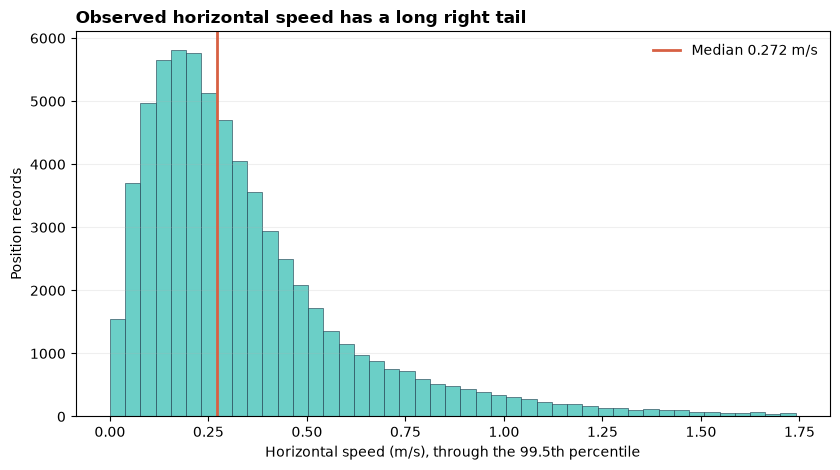

In [4]:
plt.style.use("default")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
speed = data["speed_m_s"].dropna()
shown = speed[speed <= speed.quantile(0.995)]
ax.hist(shown, bins=45, color="#6bcfc7", edgecolor="#163447", linewidth=0.4)
ax.axvline(speed.median(), color="#d76043", linewidth=2, label=f"Median {speed.median():.3f} m/s")
ax.set_title("Observed horizontal speed has a long right tail", loc="left", weight="bold")
ax.set_xlabel("Horizontal speed (m/s), through the 99.5th percentile")
ax.set_ylabel("Position records")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

The speed distribution is right-skewed. Values above the IQR fence are unusual relative to the rest of this extract, but none exceeds 3 m/s after NOAA's fill values are removed. I keep these observations because the data have already passed NOAA quality control and fast currents can occur.

### 3. Time coverage

In [5]:
monthly = (
    data.groupby("month", as_index=False)
    .agg(positions=("ID", "size"), unique_drifters=("ID", "nunique"))
)
monthly

,month,positions,unique_drifters
0,2024-01,4058,41
1,2024-02,3132,37
2,2024-03,2743,34
3,2024-04,2010,27
4,2024-05,3171,38
5,2024-06,5000,52
6,2024-07,6585,67
7,2024-08,7775,83
8,2024-09,8639,84
9,2024-10,8335,83


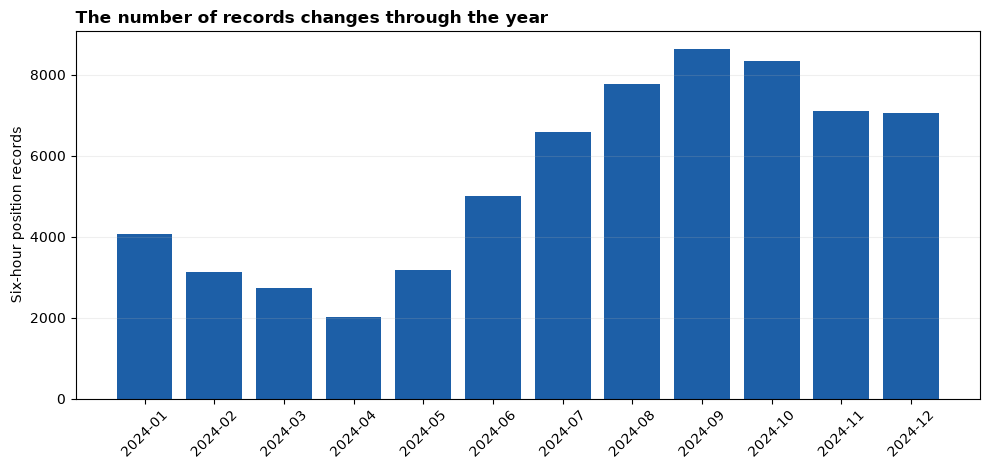

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(monthly["month"], monthly["positions"], color="#1d5fa7")
ax.set_title("The number of records changes through the year", loc="left", weight="bold")
ax.set_ylabel("Six-hour position records")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [7]:
ordered = data.sort_values(["ID", "time"]).copy()
ordered["gap_hours"] = ordered.groupby("ID")["time"].diff().dt.total_seconds() / 3600
pd.Series({
    "transitions longer than 6 hours": int(ordered["gap_hours"].gt(6).sum()),
    "largest gap in hours": float(ordered["gap_hours"].max()),
})

transitions longer than 6 hours     149.0
largest gap in hours               5538.0
dtype: float64

There are 149 within-drifter transitions longer than six hours. Because this is a geographically filtered extract, these gaps can occur when a drifter leaves the box and later re-enters. The final visualization should break the line at long gaps instead of drawing a straight segment across unobserved space.

### 4. Geographic and drogue coverage

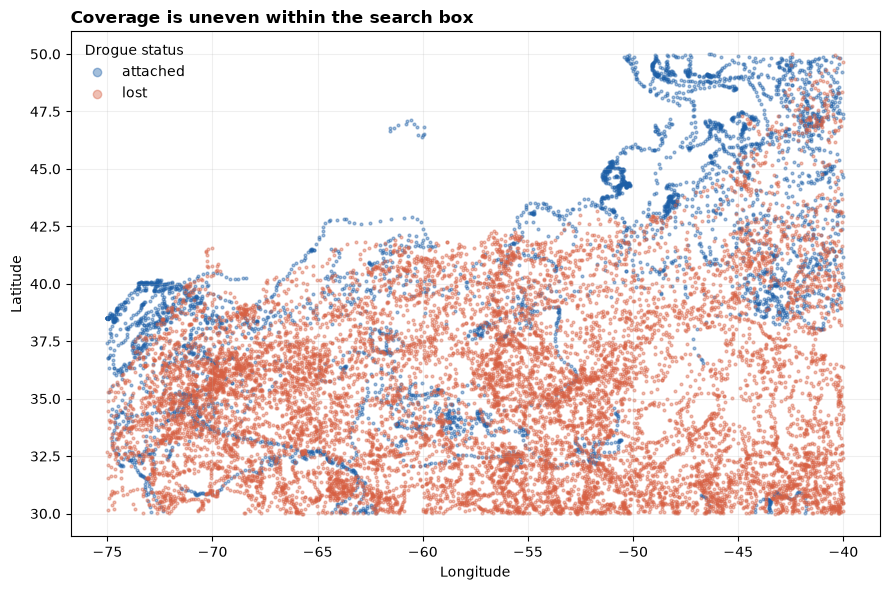

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_sample = data.iloc[::max(1, len(data) // 15000)]
colors = {"attached": "#1d5fa7", "lost": "#d76043"}
for status, group in plot_sample.groupby("drogue_status"):
    ax.scatter(group["longitude"], group["latitude"], s=4, alpha=0.4,
               c=colors.get(status, "#8a9497"), label=status)
ax.set_title("Coverage is uneven within the search box", loc="left", weight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Drogue status", frameon=False, markerscale=3)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [9]:
status_table = data["drogue_status"].value_counts().rename_axis("status").reset_index(name="positions")
status_table["share_pct"] = status_table["positions"] / len(data) * 100
status_table

,status,positions,share_pct
0,lost,47111,71.78819
1,attached,18514,28.21181


## Takeaways

1. The working extract is manageable at about 6.1 MB and is large enough to test search, filtering and route selection.
2. The route keys are clean: there are no duplicate `ID + time` combinations and no missing IDs, times or coordinates.
3. `-999999` must be treated as a fill value before calculating velocity or speed. The raw download remains unchanged, and the cleaning step is documented in code.
4. Sea-surface temperature is absent in about 10.2% of rows, so temperature should remain optional in the interface.
5. About 71.8% of positions in this extract occur after the drifter's recorded drogue-loss date. The site must show drogue status because these tracks respond more strongly to wind and waves.
6. Coverage changes by month and location. Every search result should display its date window, area and number of matching tracks.
